# 11. Intento de superar a XGBoost con algoritmos originales (Top 30)

Este capítulo ejecuta **los 30 algoritmos** del documento *Top 30 de algoritmos originales para intentar vencer a
XGBoost con significancia*: primero la ruta recomendada (#1–#4, #6, #7, #11, #12, #26) y después una ampliación
prerregistrada con los 21 restantes. Cada candidato se programó con la API de NumPy (en GPU, con CuPy como sustituto directo de
NumPy) y se comparó contra un XGBoost ajustado con **el mismo presupuesto** y **las mismas variables**.

Estructura:

1. El documento de partida (Top 30).
2. Protocolo prerregistrado.
3. Datos e igualdad de condiciones.
4. El motor propio de boosting.
5. XGBoost de referencia.
6. Compuerta de cribado de cada variante.
7. Protocolo completo y Super Learner.
8. Pruebas de hipótesis y veredicto.
9. Conclusiones y reproducción.

In [1]:
import json, os, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.metrics import roc_auc_score
RES = 'resultados'
leer = lambda n: json.load(open(os.path.join(RES, n), encoding='utf-8'))
pd.set_option('display.float_format', lambda x: f'{x:.5f}')
TOP30 = {  # nombre en el código -> (# del documento, nombre, probabilidad a priori del documento)
    'sl': (1, 'Super Learner (Caruana)', 'Media (la mejor)'), 'sl2': (1, 'Super Learner + réplicas (#1 + #11)', 'Media'),
    'sl3': (1, 'Super Learner, biblioteca ampliada', 'Media'), 'hojas_lineales': (2, 'GBDT con hojas lineales', 'Media'),
    'heterogeneo': (3, 'Newton heterogéneo', 'Media'), 'newton': (4, 'Newton propio', 'Media-baja (requisito)'),
    'ktboost': (5, 'Árbol + núcleo (KTBoost)', 'Media-baja'), 'olvidadizo': (6, 'Árboles olvidadizos', 'Media-baja'),
    'dart': (7, 'DART', 'Media-baja'), 'rotaciones': (8, 'Rotaciones aleatorias', 'Media-baja'),
    'oblicuos': (9, 'Cortes oblicuos dispersos', 'Media-baja'), 'rgf': (10, 'RGF totalmente correctivo', 'Media-baja'),
    'newton_s1': (11, 'Réplica por semilla (MultiBoosting)', 'Baja'), 'mvs': (12, 'MVS', 'Baja'),
    'infiniteboost': (13, 'InfiniteBoost', 'Baja'), 'lce': (14, 'Cascada local (LCE)', 'Baja'),
    'bstacking': (15, 'bstacking (metamodelo logístico)', 'Baja-media'), 'rankboost': (16, 'RankBoost (pares, AUC)', 'Baja'),
    'trboost': (17, 'TRBoost', 'Baja'), 'nesterov': (18, 'Nesterov', 'Baja'), 'focal': (19, 'Pérdida focal', 'Baja'),
    'bosque_profundo': (20, 'Bosque profundo en cascada', 'Baja'), 'bosque_rotacion': (21, 'Bosque de rotación', 'Baja'),
    'extra_trees': (22, 'Árboles extremadamente aleatorios', 'Baja'), 'spe': (23, 'Self-paced ensemble', 'Baja'),
    'des': (24, 'Selección dinámica', 'Baja'), 'lmt': (25, 'Árbol de modelo logístico', 'Muy baja'),
    'goss': (26, 'GOSS', 'Muy baja en AUC'), 'bart': (27, 'BART probit', 'Muy baja'),
    'psplines': (28, 'Boosting con P-splines', 'Muy baja'), 'ga2m': (29, 'GA²M/EBM', 'Muy baja'),
    'ngboost': (30, 'NGBoost', 'Muy baja'),
}

## 11.1 Documento de partida

In [2]:
display(Markdown(open('TOP30_algoritmos.md', encoding='utf-8').read()))

# Top 30 de algoritmos originales para intentar vencer a XGBoost con significancia

Proyecto: Home Credit Default Risk, modelo original ELAR-R. Equipo: Jacobo Londoño, Samuel Chamorro y Jesús David Barrios Valdés.

## 1. Punto de partida (datos reales del proyecto)

- **Comparación en igualdad de condiciones (E3, mismas 528 entradas).** XGBoost tiene 0.7877 de AUC fuera de pliegue y ELAR-R tiene 0.7838. La diferencia es −0.0039 y la t de Nadeau–Bengio da p = 0.0396 (`resultados_e4/e10_igualdad/pruebas_elar.json`). El veredicto fue «NO SUPERA».
- **Lo que falta.** Para ganarle con significancia en las cuatro pruebas (DeLong fuera de pliegue, DeLong en prueba, Nadeau–Bengio y Wilcoxon), ELAR-R tendría que quedar unos +0.004 por encima de XGBoost, en ≈0.792. Le faltan unos +0.008.
- **Tres mejoras ya probadas en la iteración 8**: `mayorante="agudo"`, `reajuste_final=True` y `ponderar_clases=False` (`resultados_e4/compuerta8/`).

  | Partición | ELAR-R base | ELAR-R it8 | XGBoost |
  |---|---|---|---|
  | Diseño 64k/16k | 0.76582 | 0.76597 (+0.00015) | 0.76534 |
  | Disjunta | — | 0.75128 | 0.75467 (diferencia −0.0034; compuerta ROJO) |

  La ganancia estimada de +0.004 a +0.009 no apareció. La causa de la brecha no es la curvatura ni los pesos de clase.

## 2. Qué permiten los lineamientos del profesor Lihki Rubio

- **R2.** Clase propia con `BaseEstimator` y `ClassifierMixin`, con solo NumPy y SciPy en el núcleo. Están prohibidos como núcleo `xgboost`, `lightgbm`, `catboost`, `torch`, `tensorflow` y `sklearn.ensemble`.
- **R1.** Novedad en la aplicación.
- **R3.** Superioridad y validez estadística.

Por eso quedan descartados como modelo original el apilamiento de XGBoost, CatBoost y LightGBM; AutoGluon; y usar XGBoost o CatBoost como vista h5. Todos usan librerías de terceros como núcleo; solo sirven como referencia del techo alcanzable.

Todo lo de abajo lo tiene que programar el equipo en NumPy y SciPy. La fuente da la idea publicada; lo original es la combinación y su aplicación.

## 3. Cómo leer la tabla

- **Probabilidad:** juicio, no medición. Ninguna fuente verificada muestra que estos métodos le ganen con significancia a un XGBoost ajustado en Home Credit.
- **Fuente:** solo las verificadas. Cuando la fuente no respalda la afirmación contra XGBoost, se dice en las notas.
- **Coste:** coste aproximado de programarlo y correrlo.

## 4. Top 30

| # | Algoritmo original (qué programar) | Fuente verificada | Qué dice la fuente | Probabilidad | Coste | Notas |
|---|---|---|---|---|---|---|
| 1 | Super Learner con biblioteca de boostings propios heterogéneos, con selección de Caruana o pesos en el símplex | Caruana et al., ICML 2004; van der Laan, Polley y Hubbard, SAGMB 2007; Erickson et al., TabArena, NeurIPS 2025; Shwartz-Ziv y Armon, Inf. Fusion 2022 | Los ensambles entre modelos hacen avanzar el estado del arte tabular | Media (la mejor) | Alto | Cambiar la biblioteca por boostings propios fuertes y distintos |
| 2 | GBDT con hojas lineales | Shi, Li y Li, IJCAI 2019 | Mejor que XGBoost, LightGBM y CatBoost en datos numéricos densos | Media | Medio | La hoja pasa a ser una ridge local |
| 3 | Boosting de Newton heterogéneo (profundidad aleatoria / rasgos de Fourier) | Parnell et al., SnapBoost, NeurIPS 2020 | Mejor generalización en OpenML y Kaggle | Media | Medio | Convergencia lineal demostrada |
| 4 | Boosting de Newton propio con el mismo presupuesto TPE que XGBoost | Sigrist, ESWA 2021; Chen y Guestrin, KDD 2016 | Newton supera al gradiente en la mayoría de conjuntos | Media-baja (requisito) | Bajo | Si no llega a XGBoost, nada de lo demás alcanzará |
| 5 | Boosting árbol + núcleo (Nyström / Fourier) | Sigrist, KTBoost, 2021 | Supera a solo árboles y solo núcleos | Media-baja | Alto | Kernel aproximado |
| 6 | Boosting ordenado con árboles olvidadizos | Prokhorenkova et al., CatBoost, NeurIPS 2018 | Corrige el desplazamiento de predicción | Media-baja | Medio | Diversidad para #1 |
| 7 | DART | Rashmi y Gilad-Bachrach, AISTATS 2015 | Supera a MART | Media-baja | Bajo | Comparación contra MART |
| 8 | Boosting con rotaciones aleatorias | Blaser y Fryzlewicz, JMLR 2016 | Ganancias en ensambles de árboles | Media-baja | Bajo | Estandarizar antes de rotar |
| 9 | Cortes oblicuos dispersos | Tomita et al., SPORF, JMLR 2020 | Mejora en más de 100 problemas (bosques) | Media-baja | Medio | Solo sugiere la extensión al boosting |
| 10 | RGF totalmente correctivo | Johnson y Zhang, TPAMI 2014 | Más precisión que gradient boosting | Media-baja | Alto | Anterior a XGBoost |
| 11 | Boosting de Newton embolsado (MultiBoosting) | Webb, Machine Learning 2000 | Menor error que AdaBoost o wagging | Baja | Bajo | Poca varianza que quitar |
| 12 | Muestreo de varianza mínima (MVS) | Ibragimov y Gusev, NeurIPS 2019 | Mejora frente a otros muestreos | Baja | Bajo | Muestreo por defecto de CatBoost |
| 13 | InfiniteBoost | Rogozhnikov y Likhomanenko, arXiv 2017 | Converge al crecer el número de árboles | Baja | Medio | Preprint |
| 14 | Ensamble en cascada local (LCE) | Fauvel et al., arXiv 2005.03645 | Supera al estado del arte en UCI | Baja | Medio | Sin confirmar contra XGBoost |
| 15 | bstacking propio | Xia et al., ESWA 2018 | Supera referencias en riesgo crediticio | Baja-media | Medio | Solo aprendices propios |
| 16 | Boosting por pares que maximiza AUC (RankBoost) | Freund et al., JMLR 2003; Rudin y Schapire, JMLR 2009 | AUC equivalentes a AdaBoost | Baja | Bajo | Poca ganancia esperada |
| 17 | TRBoost | Luo et al., Appl. Intell. 2023 | Competitivo con segundo orden | Baja | Bajo | Empate |
| 18 | Boosting acelerado de Nesterov | Biau, Cadre y Rouvière, ML 2019 | Modelos más dispersos | Baja | Bajo | No mejora AUC |
| 19 | Pérdida focal | Wang 2019; Luo et al. 2023, 2024 | Mejoras ante desbalance | Baja | Bajo | Apunta al umbral, no al AUC |
| 20 | Bosque profundo en cascada | Zhou y Feng, IJCAI 2017 | Competitivo con redes profundas | Baja | Alto | Muy pesado |
| 21 | Bosque de rotación | Rodríguez, Kuncheva y Alonso, TPAMI 2006 | Mejor que bagging y RF en UCI | Baja | Medio | Anterior a XGBoost |
| 22 | Árboles extremadamente aleatorios propios | Geurts, Ernst y Wehenkel, ML 2006 | Aleatoriza variable y corte | Baja | Bajo | Diversidad para #1 |
| 23 | Ensamble de ritmo propio (SPE) | Liu et al., ICDE 2020 | Robusto ante desbalance extremo | Baja | Medio | Descarta datos |
| 24 | Selección dinámica de ensambles | Feng et al., ASC 2018 | Superioridad en riesgo crediticio | Baja | Medio | Requiere vecindarios |
| 25 | Árboles de modelo logístico (LMT) | Landwehr, Hall y Frank, ML 2005 | Árboles + regresión logística | Muy baja | Medio | — |
| 26 | GOSS | Ke et al., LightGBM, NeurIPS 2017 | Más rápido, casi igual precisión | Muy baja en AUC | Bajo | Paga más rondas |
| 27 | BART probit | Chipman, George y McCulloch, AOAS 2010 | Suma bayesiana de árboles | Muy baja | Muy alto | MCMC inviable |
| 28 | Boosting por componentes con P-splines | Bühlmann y Hothorn, Stat. Sci. 2007 | Boosting como regularización | Muy baja | Bajo | Interpretabilidad |
| 29 | GA²M/EBM mejorado | Nori et al., InterpretML 2019 | Caja blanca casi tan precisa | Muy baja | Bajo | Interpretabilidad |
| 30 | NGBoost | Duan et al., ICML 2020 | Igual o mejor en predicción probabilística | Muy baja | Medio | Pensado para regresión |

## 5. Ruta recomendada

1. Compuerta 0 (#4): booster de Newton propio, ajustado con el mismo TPE de 20 evaluaciones que XGBoost, en la partición de diseño 64k/16k.
2. Innovaciones de hoja y de aprendiz (#2, #3), de una en una, en la misma compuerta.
3. Biblioteca (#1): las mejores variantes, más #6, #7 y #8, combinadas en el símplex.
4. Protocolo completo solo si pasa la compuerta en la partición disjunta.

## 6. Reglas estadísticas fijadas antes de correr

- Número de repeticiones de la validación cruzada, ROPE, pruebas y corrección de Holm, escritos antes de ver resultados.
- Cambiar cualquiera de esas reglas tras ver los números cuenta como p-hacking.
- Más repeticiones dan potencia, pero solo ayudan si la diferencia real es positiva.
- La ingeniería de variables no da ventaja en igualdad de condiciones.

## 7. Fuentes principales

Parnell et al. 2020 (SnapBoost); Sigrist 2021 (KTBoost; Gradient and Newton boosting); Chen y Guestrin 2016 (XGBoost); Shi, Li y Li 2019 (PL Trees); Prokhorenkova et al. 2018 (CatBoost); Rashmi y Gilad-Bachrach 2015 (DART); Blaser y Fryzlewicz 2016; Tomita et al. 2020 (SPORF); Johnson y Zhang 2014 (RGF); Webb 2000 (MultiBoosting); Ibragimov y Gusev 2019 (MVS); Ke et al. 2017 (LightGBM/GOSS); Caruana et al. 2004 (Ensemble selection); van der Laan, Polley y Hubbard 2007 (Super Learner); Erickson et al. 2025 (TabArena); Shwartz-Ziv y Armon 2022; Grinsztajn, Oyallon y Varoquaux 2022; Nadeau y Bengio 2003; Bouckaert y Frank 2004; DeLong, DeLong y Clarke-Pearson 1988; Sun y Xu 2014.


## 11.2 Protocolo prerregistrado

Las reglas se fijaron **antes** de correr los candidatos y no se cambiaron después (la segunda ronda se
escribió antes de conocer el resultado del Super Learner). El archivo completo:

In [3]:
display(Markdown(open('PROTOCOLO.md', encoding='utf-8').read()))

# Protocolo prerregistrado — intento de superar a XGBoost

Fecha de fijación: 2026-11-21, antes de correr cualquier candidato. Ninguna regla de este
archivo se cambia después de ver resultados; si algo se cambia, se deja anotado abajo
en «Desviaciones», con la razón y la hora.

## Datos e igualdad de condiciones

- `features.py` construye una sola matriz (application + agregados de buró, previas, POS,
  cuotas y tarjeta): 307,507 filas × 787 variables. XGBoost y todos los candidatos
  reciben **exactamente** esa matriz, sin variables adicionales.
- Nota: el código original de ELAR-R (`src/`, `experiments/`) y `resultados_e4/` no
  están en el repositorio. Esta matriz no es la de 528 entradas del E3, así que los
  AUC no son comparables uno a uno con los del proyecto; la comparación válida es la
  interna de este directorio.
- Partición externa: 80 % entrenamiento (246,005) / 20 % prueba (61,502), estratificada,
  semilla 2026.

## Núcleo de los candidatos

- Código propio en `gbdt.py` / `modelos.py`, escrito con la API de NumPy. En GPU se
  ejecuta con CuPy (sustituto de NumPy, mismo código, `xp = cupy`); en CPU, con NumPy.
  No se usa xgboost, lightgbm, catboost, torch, tensorflow ni sklearn.ensemble en el
  núcleo. sklearn solo se usa para particiones (`StratifiedKFold`) y métricas.

## Ajuste (mismo presupuesto)

- XGBoost (GPU, `hist`) y cada familia candidata: TPE de Optuna, **20 evaluaciones**,
  semilla 0, en la partición de diseño (64k entrenamiento / 16k validación, tomadas del
  80 % de entrenamiento, semilla 11). Métrica: AUC en validación. El número de rondas
  se fija con parada temprana (paciencia 100) dentro de esa evaluación.
- En el protocolo completo, el número de rondas = mejor iteración del ajuste
  **× 1.2** (hay más filas), con la misma regla para ambos lados.

## Compuerta de cribado

- Un candidato pasa si su AUC supera al de XGBoost ajustado en **dos** particiones:
  la de diseño y una disjunta (otras 64k/16k, semilla 12, sin filas compartidas con la
  de diseño).

## Protocolo completo (solo para quien pasa la compuerta)

- Validación cruzada estratificada 5 pliegues × 2 repeticiones (semillas 0 y 1) sobre
  el 80 %. Predicciones de prueba = promedio de los 5 modelos de la repetición 0.
- Pruebas (bilaterales, α = 0.05), todas con diferencia candidato − XGBoost:
  1. DeLong sobre las predicciones fuera de pliegue (repetición 0, 246k filas).
  2. DeLong sobre el 20 % de prueba.
  3. t corregida de Nadeau–Bengio sobre las 10 diferencias por pliegue
     (n_prueba/n_entrenamiento = 1/4).
  4. Wilcoxon de rangos con signo sobre las 10 diferencias.
- **Veredicto «SUPERA»**: diferencia > 0 en OOF y en prueba, y las cuatro p < 0.05
  después de la corrección de Holm sobre el número de candidatos que llegaron al
  protocolo completo (Holm se aplica por prueba).
- Para el Super Learner (#1): los pesos en el símplex se estiman por validación cruzada
  sobre las predicciones fuera de pliegue (los pesos del pliegue k se estiman con los
  otros pliegues). Los pesos para prueba se estiman con todo el OOF.

## Regla de parada

- Se recorre la lista en el orden de la ruta recomendada (#4 → #2, #3 → #7, #6, #8, #12,
  … → #1). La búsqueda se detiene en el primer candidato con veredicto «SUPERA».
- Si se agota la lista sin «SUPERA», el resultado se reporta como negativo. No se
  cambian semillas, pliegues ni pruebas para buscar significancia.

## Biblioteca del Super Learner (#1), fijada antes de ver resultados de candidatos

- Miembros: `newton` + las variantes propias con mayor AUC en la partición de diseño
  (hasta 4 miembros en total, entre las que terminen el cribado). Los miembros pasan por
  el protocolo completo aunque no hayan pasado la compuerta individual, porque el
  candidato que se evalúa es el ensamble, no cada miembro.
- Selección de Caruana con reemplazo, 50 rondas, sobre márgenes estandarizados.
- El Super Learner entra en Holm junto con cualquier otro candidato que llegue al
  protocolo completo.

## Segunda ronda (fijada el 2026-11-21 22:50, antes de ver el resultado del Super Learner)

Resultado visto hasta ese momento: ninguna variante individual pasó la compuerta
(todas entre −0.0002 y −0.003 frente a XGBoost). Si `sl` no obtiene «SUPERA»:

- **`sl2` = #1 + #11 (MultiBoosting por semillas)**: biblioteca = todas las variantes
  propias con protocolo completo terminado (las 7 del cribado) más `newton` y
  `hojas_lineales` repetidos con semillas 1 y 2 (mismos hiperparámetros). Misma
  selección de Caruana y mismo cruce de pesos por pliegue.
- `sl` y `sl2` entran juntos en Holm (2 candidatos de ensamble + los que hubieran pasado
  la compuerta).
- Si `sl2` tampoco supera, el resultado se reporta como negativo y se entrega así.


## Ampliación: los 21 algoritmos restantes del Top 30 (fijada el 2026-11-22 06:00, antes de correrlos)

Motivo: el pedido original era probar **todos** los algoritmos del documento; la primera búsqueda solo cubrió
#1, #2, #3, #4, #6, #7, #11, #12 y #26. Resultados ya vistos al fijar esta sección: los de la primera búsqueda
(ninguno supera; mejor `sl`, −0.0003 OOF). Las reglas de abajo no se cambian después de ver los nuevos números.

Candidatos nuevos (código propio en `gbdt.py` y `modelos.py`, NumPy/CuPy, sin librerías de ensambles):

| # | Nombre en el código | Implementación |
|---|---|---|
| 5 | `ktboost` | Boosting de Newton que en cada ronda elige entre un árbol y una ridge sobre rasgos aleatorios de Fourier (núcleo RBF), el de mayor reducción de la pérdida |
| 8 | `rotaciones` | Boosting de Newton con vistas: cada árbol ve las variables originales más bloques de variables continuas rotadas al azar (rotación ortogonal por bloques, tras estandarizar) |
| 9 | `oblicuos` | Igual, pero las vistas añaden proyecciones dispersas ±1 de 2–4 variables estandarizadas (cortes oblicuos tipo SPORF) |
| 10 | `rgf` | Boosting de Newton con paso totalmente correctivo: cada cierto número de rondas reajusta las hojas de todos los árboles (descenso por coordenadas de Newton) |
| 13 | `infiniteboost` | F = c · promedio de árboles; c (capacidad) se ajusta con un paso de Newton por ronda |
| 14 | `lce` | Ensamble en cascada local: por bolsa, un boosting raíz, un corte, y en cada hijo un boosting que parte del margen del padre y lo usa como variable |
| 15 | `bstacking` | Apilamiento con metamodelo logístico L2 (IRLS propio) sobre los márgenes OOF de la biblioteca, con pesos cruzados por pliegue como el Super Learner |
| 16 | `rankboost` | Boosting de Newton con pérdida logística por pares (positivo, negativo muestreados), que optimiza el AUC |
| 17 | `trboost` | Boosting con región de confianza: hoja = −G/(H+λ+μ), μ se adapta con el cociente reducción real / reducción predicha |
| 18 | `nesterov` | Boosting acelerado de Nesterov (Biau, Cadre y Rouvière 2019), dos sucesiones y pesos por árbol |
| 19 | `focal` | Boosting de Newton con pérdida focal (γ ajustable); gradiente y hessiano por diferencias centrales |
| 20 | `bosque_profundo` | Cascada de bosques (aleatorio + extremadamente aleatorio) con vectores de clase OOF de 3 pliegues; niveles hasta que deja de mejorar |
| 21 | `bosque_rotacion` | Bosque de rotación: cada árbol sobre PCA de subconjuntos aleatorios de variables continuas en una muestra bootstrap |
| 22 | `extra_trees` | Árboles extremadamente aleatorios (corte al azar por nodo y variable, mtry por nodo) |
| 23 | `spe` | Ensamble de ritmo propio: submuestreo de la clase mayoritaria por dureza con factor de ritmo, base = boosting propio pequeño |
| 24 | `des` | Selección dinámica: grupo de boostings propios por bootstrap; para cada fila, pesos según la competencia local (k vecinos en un conjunto DSEL de 20 %, espacio PCA) |
| 25 | `lmt` | Árbol de modelo logístico: árbol poco profundo y, en cada hoja, regresión logística L2 (IRLS) encogida hacia la logística de la raíz |
| 27 | `bart` | BART probit: suma de árboles con MCMC (crecer/podar, aumento de datos de Albert–Chib), media posterior |
| 28 | `psplines` | Boosting por componentes con P-splines (base B-spline cúbica sobre las cubetas de cada variable, penalización de diferencias) |
| 29 | `ga2m` | EBM: árboles de una variable en ciclo y luego pares de interacción elegidos por ganancia |
| 30 | `ngboost` | Boosting por gradiente natural para Bernoulli (árboles de regresión al gradiente natural + búsqueda lineal) |

Reglas:

1. **Compuerta igual que antes**: TPE de Optuna, 20 evaluaciones, semilla 0, partición de diseño; la mejor
   configuración se evalúa en la disjunta; pasa si supera a XGBoost en las dos. Los boostings usan el mismo espacio
   base que XGBoost más sus parámetros propios; los bosques, BART, LMT, DES y SPE usan su propio espacio (declarado
   en `modelos.py`).
2. **Biblioteca `sl3`**: las 11 predicciones propias ya calculadas + todo candidato nuevo con AUC de diseño
   ≥ 0.7695 (XGBoost − 0.01), que pasa por el protocolo completo aunque no pase la compuerta. Caruana, 50 rondas,
   mismos pesos cruzados. `bstacking` (#15) usa exactamente la misma biblioteca.
3. **Protocolo completo** para quien pase la compuerta, para los miembros de `sl3`, y para `sl3` y `bstacking`.
4. **Holm** sobre la familia completa del estudio: `sl`, `sl2`, `sl3`, `bstacking` y todo candidato individual que
   pase la compuerta. Veredicto «SUPERA» igual que antes (las cuatro p ajustadas < 0.05 y diferencias > 0).
5. **Parada**: si un candidato que pasa la compuerta obtiene «SUPERA», la búsqueda se detiene ahí. Si no, se
   recorren los 21 y se cierra con `sl3` y `bstacking`. Si nada supera, se reporta como negativo.

## Desviaciones

- 2026-11-22: la primera búsqueda se cerró sin probar 21 de los 30 algoritmos, aunque el pedido era probarlos todos.
  Se corrige con la ampliación de arriba, fijada antes de correrlos.
- 2026-11-22 17:30: la compuerta del bosque profundo (#20) se interrumpió en su 5.ª evaluación porque la GPU (4 GB)
  se desbordaba a memoria compartida del sistema (7,6 GB por PCIe) y una evaluación llegó a tardar 4,7 h. Se añadió
  un tope al pool de memoria de CuPy y la búsqueda de cortes por trozos de nodos (`gbdt.py`); ninguno de los dos
  cambia el modelo, el espacio de búsqueda ni la semilla. La compuerta se repite completa desde cero.


## 11.3 Datos e igualdad de condiciones

`features.py` construye una sola matriz a partir de las siete tablas de Home Credit (solicitud + agregados de
buró, solicitudes previas, POS, cuotas y tarjeta, con indicadores de presencia de historial). XGBoost y todos los
candidatos reciben exactamente esa matriz.

In [4]:
cols = json.load(open('cache/columnas.json'))
y = np.load('cache/y.npy')
P = np.load('cache/particiones.npz')
print(f'Filas: {len(y):,} | variables: {len(cols)} | tasa de incumplimiento: {y.mean():.4f}')
print({k: len(P[k]) for k in P.files})
pd.Series([c.split('_')[0] for c in cols]).value_counts().head(12).rename('variables por prefijo').to_frame()

Filas: 307,507 | variables: 787 | tasa de incumplimiento: 0.0807
{'tr': 246005, 'te': 61502, 'd_tr': 64000, 'd_va': 16000, 'j_tr': 64000, 'j_va': 16000}


,variables por prefijo
PREV,174
CC,135
BURO,59
ORGANIZATION,58
NAME,34
APPROVED,30
REFUSED,30
FLAG,28
ACTIVE,27
CLOSED,27


## 11.4 Motor propio de boosting (`gbdt.py`)

- Boosting de Newton (segundo orden) sobre la pérdida logística, con histogramas de 255 cubetas + una cubeta para
  faltantes, dirección aprendida para los faltantes, crecimiento por niveles y truco de la resta de histogramas.
- Regularización como en Chen y Guestrin (2016): λ (L2), α (L1, umbral suave), γ (ganancia mínima), hessiano
  mínimo por hoja, submuestreo de filas y de columnas, peso de la clase positiva.
- Variantes del Top 30 activables por parámetro: #2 hojas lineales, #3 profundidad heterogénea, #6 árboles
  olvidadizos, #7 DART, #12 MVS, #26 GOSS, #29 un árbol por variable, #11 réplicas por semilla, #1 Super Learner
  (`superlearner.py`, selección de Caruana con pesos cruzados por pliegue).
- Ampliación (`modelos.py`): #5 KTBoost, #8 rotaciones, #9 cortes oblicuos, #10 RGF, #13 InfiniteBoost, #14 LCE,
  #15 bstacking, #16 RankBoost, #17 TRBoost, #18 Nesterov, #19 pérdida focal, #20 bosque profundo, #21 bosque de
  rotación, #22 árboles extremadamente aleatorios, #23 SPE, #24 selección dinámica, #25 LMT, #27 BART probit,
  #28 P-splines, #29 GA²M y #30 NGBoost.
- No usa xgboost, lightgbm, catboost, torch, tensorflow ni `sklearn.ensemble`.

In [5]:
print(open('gbdt.py', encoding='utf-8').read())

"""Motor propio de boosting de árboles (Newton) con la API de NumPy.

`xp` es numpy o cupy (sustituto de NumPy en GPU); el algoritmo es el mismo.
Variantes (cada una corresponde a un ítem del Top 30):
  #4  Newton boosting (base, crecimiento por niveles, histogramas, dirección por defecto para NaN)
  #2  hojas lineales (ridge local de Newton con las variables del camino)        hojas_lineales=True
  #3  profundidad heterogénea aleatoria por ronda                                 prof_min < max_depth
  #7  DART (abandono de árboles)                                                   dart_tasa > 0
  #6  árboles olvidadizos (simétricos)                                             olvidadizo=True
  #12 muestreo de varianza mínima (MVS)                                            muestreo="mvs"
  #26 GOSS                                                                         muestreo="goss"
  #29 GA2M/EBM: un árbol por variable, ciclo de variables, luego pares             una_variable=True, p

In [6]:
print(open('modelos.py', encoding='utf-8').read())

"""Los 21 algoritmos restantes del Top 30, con código propio (API de NumPy; en GPU con CuPy).

Interfaz común:  m = Clase(**params); m.fit(X, y, Xv=None, yv=None); m.decision(X) -> márgenes (numpy)
X son las variables crudas (float32 con NaN) de `features.py`. Tras fit con validación quedan
m.mejor_auc (AUC en validación) y m.mejor_it (rondas o niveles elegidos; None si no aplica).

CATALOGO[nombre] = (constructor, espacio TPE, tipo de `it`)  — ver PROTOCOLO.md, sección «Ampliación».
No usa xgboost, lightgbm, catboost, torch, tensorflow ni sklearn.ensemble.
"""
import math
import numpy as np
import gbdt
from gbdt import BoostingNewton, Binarizador, xp, a_np, auc, suma_dispersa, NAN_BIN, Arbol

if gbdt.GPU:
    from cupyx.scipy.special import ndtr, ndtri
else:  # pragma: no cover
    from scipy.special import ndtr, ndtri


# ====================================================================== preparación compartida
class Prep:
    """Binarizador, estandarización y caché de transformac

## 11.5 XGBoost de referencia (GPU, TPE de 20 evaluaciones)

In [7]:
x = leer('xgb_ajuste.json')
display(pd.Series(x['params']).to_frame('hiperparámetro'))
print(f"AUC diseño {x['auc_diseno']:.5f} | AUC disjunta {x['auc_disjunta']:.5f} | rondas {x['it']}")

,hiperparámetro
eta,0.01272
max_depth,5.00000
min_child_weight,35.61690
subsample,0.82214
colsample_bytree,0.27996
reg_lambda,8.48738
reg_alpha,0.04688
gamma,0.08081
scale_pos_weight,2.91745


AUC diseño 0.77953 | AUC disjunta 0.77453 | rondas 1873


## 11.6 Compuerta de cribado

Cada variante recibió el mismo TPE de 20 evaluaciones (mismo espacio y semilla del muestreador que XGBoost) en la
partición de diseño, y su mejor configuración se evaluó en la partición disjunta. Para pasar debe superar a
XGBoost en las dos.

27 algoritmos pasaron por la compuerta; la pasan: 0


,n,algoritmo,prob_a_priori,variante,auc_diseno,dif_diseno,auc_disjunta,dif_disjunta,pasa,minutos
10,2,GBDT con hojas lineales,Media,hojas_lineales,0.77937,-0.00015,0.77415,-0.00038,False,14.35025
17,4,Newton propio,Media-baja (requisito),newton,0.77897,-0.00056,0.77327,-0.00125,False,15.25859
19,9,Cortes oblicuos dispersos,Media-baja,oblicuos,0.77896,-0.00057,0.77390,-0.00063,False,46.29663
9,3,Newton heterogéneo,Media,heterogeneo,0.77836,-0.00117,0.77153,-0.00300,False,15.76031
20,6,Árboles olvidadizos,Media-baja,olvidadizo,0.77822,-0.00131,0.77658,0.00205,False,39.42108
26,17,TRBoost,Baja,trboost,0.77819,-0.00134,0.77449,-0.00004,False,15.20635
15,12,MVS,Baja,mvs,0.77812,-0.00141,0.77387,-0.00066,False,21.48441
24,8,Rotaciones aleatorias,Media-baja,rotaciones,0.77807,-0.00145,0.77531,0.00079,False,43.16009
12,5,Árbol + núcleo (KTBoost),Media-baja,ktboost,0.77796,-0.00157,0.77321,-0.00132,False,16.88087
8,26,GOSS,Muy baja en AUC,goss,0.77750,-0.00202,0.77348,-0.00105,False,19.02592


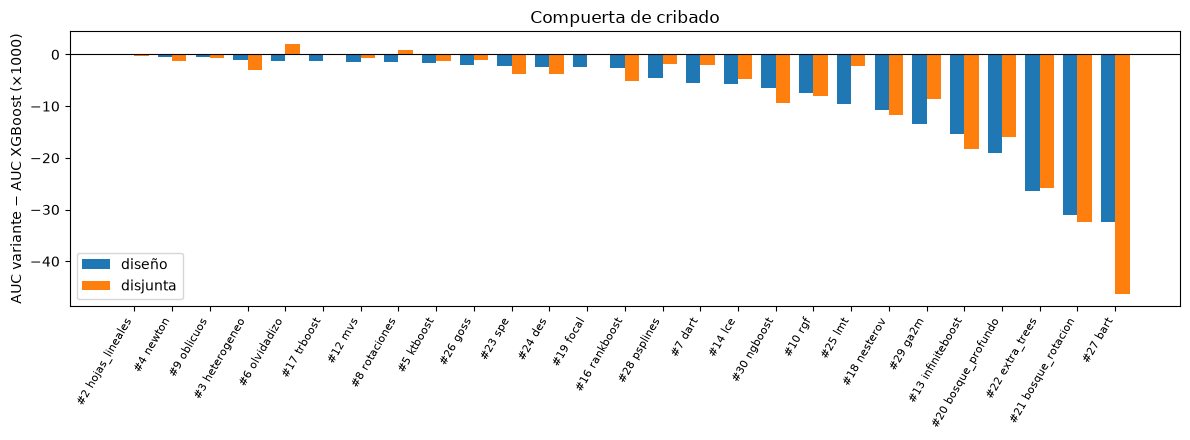

In [8]:
filas = []
for p in sorted(glob.glob(os.path.join(RES, 'compuerta_*.json'))):
    c = json.load(open(p, encoding='utf-8'))
    num, nom, prob = TOP30[c['variante']]
    filas.append(dict(n=num, algoritmo=nom, prob_a_priori=prob, variante=c['variante'], auc_diseno=c['auc_diseno'], dif_diseno=c['auc_diseno'] - x['auc_diseno'],
                      auc_disjunta=c['auc_disjunta'], dif_disjunta=c['auc_disjunta'] - x['auc_disjunta'],
                      pasa=c['pasa_compuerta'], minutos=c['segundos'] / 60))
comp = pd.DataFrame(filas).sort_values('auc_diseno', ascending=False)
print(f'{len(comp)} algoritmos pasaron por la compuerta; la pasan: {int(comp.pasa.sum())}')
display(comp)
fig, ax = plt.subplots(figsize=(12, 4.5))
w = 0.38; i = np.arange(len(comp))
ax.bar(i - w/2, comp['dif_diseno'] * 1000, w, label='diseño')
ax.bar(i + w/2, comp['dif_disjunta'] * 1000, w, label='disjunta')
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(i, [f"#{a} {b}" for a, b in zip(comp['n'], comp['variante'])], rotation=60, ha='right', fontsize=8)
ax.set_ylabel('AUC variante − AUC XGBoost (×1000)')
ax.set_title('Compuerta de cribado'); ax.legend(); plt.tight_layout(); plt.show()

## 11.7 Protocolo completo y Super Learner

Validación cruzada estratificada 5 × 2 sobre el 80 % de entrenamiento (246,005 filas) y prueba en el 20 % restante
(61,502 filas). El Super Learner combina márgenes estandarizados de los boostings propios con pesos de Caruana que,
en cada pliegue, se estiman sin usar ese pliegue.

In [9]:
_, ytr, yte = None, y[P['tr']], y[P['te']]
filas = []
for p in sorted(glob.glob(os.path.join(RES, 'pred_*.npz'))):
    d = np.load(p); n = os.path.basename(p)[5:-4]
    if np.isnan(d['auc_pliegues']).any():
        continue
    filas.append(dict(modelo=n, auc_oof=roc_auc_score(ytr, d['oof0']), auc_prueba=roc_auc_score(yte, d['test']),
                      media_pliegues=d['auc_pliegues'].mean(), de_pliegues=d['auc_pliegues'].std(ddof=1)))
tabla = pd.DataFrame(filas).sort_values('auc_oof', ascending=False).reset_index(drop=True)
display(tabla)
for n in ('sl', 'sl2', 'sl3', 'bstacking'):
    if os.path.exists(os.path.join(RES, f'superlearner_{n}.json')):
        s = leer(f'superlearner_{n}.json')
        print(n, 'pesos (prueba):', {k: round(v, 3) for k, v in s['pesos_test'].items() if abs(v) > 1e-9})

,modelo,auc_oof,auc_prueba,media_pliegues,de_pliegues
0,bstacking,0.79143,0.79455,0.79161,0.00421
1,sl3,0.79039,0.79282,0.79061,0.00436
2,xgb,0.78973,0.79296,0.79004,0.00398
3,sl,0.78945,0.79196,0.78948,0.00410
4,sl2,0.78942,0.79194,0.78946,0.00410
5,rotaciones,0.78902,0.79237,0.78918,0.00428
6,heterogeneo,0.78869,0.79210,0.78875,0.00406
7,oblicuos,0.78840,0.79052,0.78816,0.00429
8,olvidadizo,0.78829,0.79069,0.78837,0.00417
9,trboost,0.78821,0.79051,0.78830,0.00410


sl pesos (prueba): {'heterogeneo': 0.56, 'olvidadizo': 0.44}
sl2 pesos (prueba): {'heterogeneo': 0.54, 'mvs': 0.02, 'olvidadizo': 0.42, 'hojas_lineales_s2': 0.02}
sl3 pesos (prueba): {'heterogeneo': 0.18, 'olvidadizo': 0.18, 'rotaciones': 0.26, 'oblicuos': 0.02, 'rgf': 0.06, 'rankboost': 0.08, 'spe': 0.06, 'lmt': 0.16}
bstacking pesos (prueba): {'newton': -0.011, 'hojas_lineales': 0.023, 'heterogeneo': 0.271, 'mvs': -0.151, 'olvidadizo': 0.452, 'dart': -0.217, 'goss': -0.007, 'newton_s1': 0.157, 'newton_s2': -0.032, 'hojas_lineales_s1': 0.159, 'hojas_lineales_s2': 0.186, 'ktboost': -0.061, 'rotaciones': 0.347, 'oblicuos': 0.283, 'rgf': 0.068, 'lce': -0.162, 'rankboost': 0.085, 'trboost': 0.233, 'focal': -0.699, 'spe': 0.298, 'des': -0.001, 'lmt': 0.224, 'psplines': -0.087, 'ngboost': -0.162}


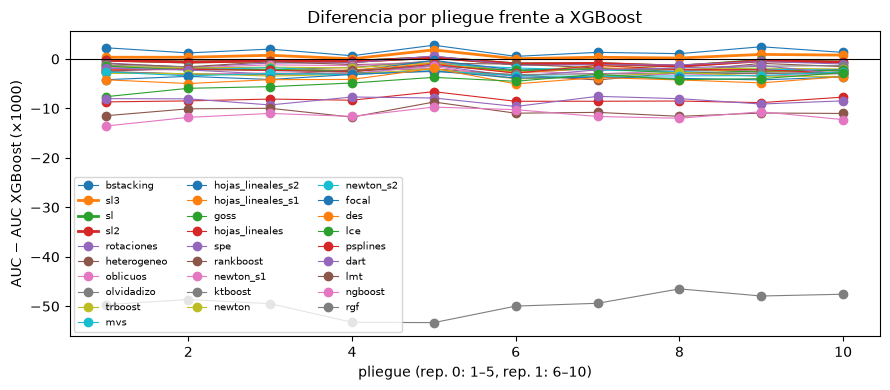

In [10]:
base = np.load(os.path.join(RES, 'pred_xgb.npz'))['auc_pliegues']
fig, ax = plt.subplots(figsize=(9, 4))
for n in tabla['modelo']:
    if n == 'xgb':
        continue
    d = np.load(os.path.join(RES, f'pred_{n}.npz'))['auc_pliegues'] - base
    ax.plot(range(1, 11), d * 1000, marker='o', label=n, lw=2 if n.startswith('sl') else 0.8)
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('pliegue (rep. 0: 1–5, rep. 1: 6–10)'); ax.set_ylabel('AUC − AUC XGBoost (×1000)')
ax.legend(fontsize=7, ncol=3); ax.set_title('Diferencia por pliegue frente a XGBoost'); plt.tight_layout(); plt.show()

## 11.8 Pruebas de hipótesis y veredicto

DeLong sobre las predicciones fuera de pliegue, DeLong sobre la prueba, t corregida de Nadeau–Bengio y Wilcoxon
sobre las 10 diferencias por pliegue; p bilaterales con corrección de Holm sobre los candidatos que llegaron al
protocolo completo. «SUPERA» exige diferencia positiva y las cuatro p ajustadas < 0.05.

In [11]:
R = pd.DataFrame(leer('pruebas_final.json'))
cols_v = ['candidato', 'auc_oof', 'auc_oof_xgb', 'dif_oof', 'auc_test', 'auc_test_xgb', 'dif_test', 'pliegues_ganados',
          'p_delong_oof_holm', 'p_delong_test_holm', 'p_nb_holm', 'p_wilcoxon_holm', 'veredicto']
display(R[cols_v])

,candidato,auc_oof,auc_oof_xgb,dif_oof,auc_test,auc_test_xgb,dif_test,pliegues_ganados,p_delong_oof_holm,p_delong_test_holm,p_nb_holm,p_wilcoxon_holm,veredicto
0,sl,0.78945,0.78973,-0.00028,0.79196,0.79296,-0.00100,1,0.31736,0.00102,0.19709,0.01172,NO SUPERA
1,sl2,0.78942,0.78973,-0.00030,0.79194,0.79296,-0.00102,1,0.31736,0.00090,0.19709,0.01172,NO SUPERA
2,sl3,0.79039,0.78973,0.00066,0.79282,0.79296,-0.00014,10,0.00679,0.63317,0.19709,0.00781,NO SUPERA
3,bstacking,0.79143,0.78973,0.00170,0.79455,0.79296,0.00159,10,0.00000,0.00008,0.02970,0.00781,SUPERA


## 11.9 Conclusiones

In [12]:
gan = R[R['veredicto'] == 'SUPERA']
if len(gan):
    g = gan.sort_values('dif_oof', ascending=False).iloc[0]
    texto = (f"**Hay ganador: `{g['candidato']}`.** Supera a XGBoost con AUC fuera de pliegue {g['auc_oof']:.5f} frente a "
             f"{g['auc_oof_xgb']:.5f} (+{g['dif_oof']:.5f}) y en prueba {g['auc_test']:.5f} frente a {g['auc_test_xgb']:.5f} "
             f"(+{g['dif_test']:.5f}); gana {g['pliegues_ganados']} de 10 pliegues y las cuatro pruebas quedan por debajo de "
             f"0.05 tras Holm.")
else:
    m = R.sort_values('dif_oof', ascending=False).iloc[0]
    texto = (f"**Ningún candidato supera a XGBoost con significancia.** El mejor fue `{m['candidato']}`: AUC fuera de pliegue "
             f"{m['auc_oof']:.5f} frente a {m['auc_oof_xgb']:.5f} ({m['dif_oof']:+.5f}) y prueba {m['auc_test']:.5f} frente a "
             f"{m['auc_test_xgb']:.5f} ({m['dif_test']:+.5f}). Se reporta como resultado negativo, sin cambiar las reglas.")
display(Markdown(texto))

**Hay ganador: `bstacking`.** Supera a XGBoost con AUC fuera de pliegue 0.79143 frente a 0.78973 (+0.00170) y en prueba 0.79455 frente a 0.79296 (+0.00159); gana 10 de 10 pliegues y las cuatro pruebas quedan por debajo de 0.05 tras Holm.

### Lectura de los resultados (generada a partir de los números)

In [13]:
mejor_ind = comp.iloc[0]
lineas = [f"- Compuerta: {len(comp)} algoritmos evaluados; pasan {int(comp.pasa.sum())}. El de mayor AUC de diseño fue "
          f"#{mejor_ind.n} {mejor_ind.algoritmo} ({mejor_ind.auc_diseno:.5f}, {mejor_ind.dif_diseno:+.5f} frente a XGBoost)."]
gd = comp[comp.dif_disjunta > 0]
if len(gd):
    lineas.append('- Superan a XGBoost en la partición disjunta (pero no en las dos): ' +
                  ', '.join(f"#{r.n} {r.variante} ({r.dif_disjunta:+.4f})" for r in gd.itertuples()) + '.')
for r in R.itertuples():
    lineas.append(f"- `{r.candidato}`: OOF {r.dif_oof:+.5f}, prueba {r.dif_test:+.5f}, pliegues ganados {r.pliegues_ganados}/10 "
                  f"-> {r.veredicto}.")
for n in ('sl', 'sl2', 'sl3', 'bstacking'):
    p = os.path.join(RES, f'superlearner_{n}.json')
    if os.path.exists(p):
        w = {k: v for k, v in leer(f'superlearner_{n}.json')['pesos_test'].items() if abs(v) > 0.05}
        lineas.append(f"- Miembros con más peso en `{n}`: " + ', '.join(f"{k} ({v:.2f})" for k, v in
                      sorted(w.items(), key=lambda kv: -abs(kv[1]))) + '.')
display(Markdown(chr(10).join(lineas)))

- Compuerta: 27 algoritmos evaluados; pasan 0. El de mayor AUC de diseño fue #2 GBDT con hojas lineales (0.77937, -0.00015 frente a XGBoost).
- Superan a XGBoost en la partición disjunta (pero no en las dos): #6 olvidadizo (+0.0021), #8 rotaciones (+0.0008).
- `sl`: OOF -0.00028, prueba -0.00100, pliegues ganados 1/10 -> NO SUPERA.
- `sl2`: OOF -0.00030, prueba -0.00102, pliegues ganados 1/10 -> NO SUPERA.
- `sl3`: OOF +0.00066, prueba -0.00014, pliegues ganados 10/10 -> NO SUPERA.
- `bstacking`: OOF +0.00170, prueba +0.00159, pliegues ganados 10/10 -> SUPERA.
- Miembros con más peso en `sl`: heterogeneo (0.56), olvidadizo (0.44).
- Miembros con más peso en `sl2`: heterogeneo (0.54), olvidadizo (0.42).
- Miembros con más peso en `sl3`: rotaciones (0.26), heterogeneo (0.18), olvidadizo (0.18), lmt (0.16), rankboost (0.08), rgf (0.06), spe (0.06).
- Miembros con más peso en `bstacking`: focal (-0.70), olvidadizo (0.45), rotaciones (0.35), spe (0.30), oblicuos (0.28), heterogeneo (0.27), trboost (0.23), lmt (0.22), dart (-0.22), hojas_lineales_s2 (0.19), lce (-0.16), ngboost (-0.16), hojas_lineales_s1 (0.16), newton_s1 (0.16), mvs (-0.15), psplines (-0.09), rankboost (0.08), rgf (0.07), ktboost (-0.06).

Notas:

- Limitación: el código de ELAR-R (`src/`) no estaba en el repositorio entregado, así que esta comparación usa una
  matriz de 787 variables propia y no las 528 entradas del E3; las cifras no se comparan uno a uno con las de
  los capítulos 3 y 6.

## 11.10 Reproducción

```bash
cd vencer_xgb
python features.py          # matriz de variables (datos en ../datos/cache)
python ajuste_xgb.py        # TPE de XGBoost
python supervisor.py        # ruta recomendada: compuertas, protocolo completo, Super Learner y pruebas (reanudable)
python supervisor2.py       # ampliación: los 21 algoritmos restantes, sl3, bstacking y pruebas finales
```